# ⚡ VoltRelay Energy — Operations Analytics
## Gradient Learnings Data Analytics Hackathon 2025
**Problem:** Understand what is driving service failures, rider churn, and margin erosion across VoltRelay's 6-city battery-swapping network (Jan 2024 – Jun 2025).

**Analyst Role:** Data Analyst – Operations & Customer Experience

---
### Dataset
| File | Rows | Description |
|------|------|-------------|
| swap_events.csv | 3,877,013 | Every swap attempt |
| station_hourly_status.csv | 1,487,712 | Hourly station telemetry |
| riders.csv | 20,000 | Rider profiles |
| batteries.csv | 6,500 | Battery pack asset ledger |
| support_tickets.csv | 44,000 | Customer complaints |
| stations.csv | 152 | Station reference |
| city_daily_context.csv | 3,282 | Weather & calendar context |
| fleet_partners.csv | 12 | B2B partner contracts |

**Note:** The swap_events file was unavailable (empty zip) for this submission. The analysis uses all other 7 files. Where swap-level data is referenced, conclusions are derived from station telemetry and support ticket proxies.
### Running in VS Code (Windows)
1. Open the `VoltRelay_Analytics` project folder in VS Code.
2. Install the Python and Jupyter extensions.
3. Create and activate a virtual environment, then install the packages listed in `requirements.txt`.
4. Keep the seven CSV files inside the `data` folder beside this notebook.
5. Open this notebook and select the project's `.venv` Python kernel.
6. Run the cells from top to bottom. Charts are saved in `outputs/`.

**Expected local folder structure**
```text
VoltRelay_Analytics/
├── VoltRelay_Analytics_Notebook_VSCode.ipynb
├── requirements.txt
├── data/
│   ├── riders.csv
│   ├── batteries.csv
│   ├── stations.csv
│   ├── fleet_partners.csv
│   ├── support_tickets.csv
│   ├── city_daily_context.csv
│   └── station_hourly_status.csv
└── outputs/
```


In [1]:
# ============================================================
# SECTION 1: SETUP & DATA LOADING
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')
from pathlib import Path

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Style
plt.rcParams.update({
    'figure.facecolor': '#1a1d27',
    'axes.facecolor': '#22263a',
    'axes.edgecolor': '#3d4166',
    'axes.labelcolor': '#9ca3c0',
    'xtick.color': '#9ca3c0',
    'ytick.color': '#9ca3c0',
    'text.color': '#e8eaf6',
    'grid.color': '#2d3148',
    'grid.linestyle': '--',
    'grid.alpha': 0.5,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 13,
    'axes.titleweight': 'bold'
})
ACCENT = ['#4f8ef7','#f7c94f','#4ff7a0','#f74f4f','#f97316','#bf4ff7']

print('Libraries loaded. Begin data loading...')

Libraries loaded. Begin data loading...


In [3]:
# ============================================================
# DATA LOADING — VS CODE / LOCAL WINDOWS
# ============================================================
# Keep the seven CSV files in the project's ./data folder.
# The swap_events.csv file is intentionally not required because
# it was unavailable for the original submission.

from pathlib import Path

required_files = [
    "riders.csv",
    "batteries.csv",
    "stations.csv",
    "fleet_partners.csv",
    "support_tickets.csv",
    "city_daily_context.csv",
    "station_hourly_status.csv",
]

DATA_DIR = Path.cwd() / "data"
OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find the data folder: {DATA_DIR}\n"
        "Open the VoltRelay_Analytics project folder in VS Code, "
        "and create a folder named 'data' beside this notebook."
    )

missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        "Missing required CSV file(s) in the data folder:\n- "
        + "\n- ".join(missing_files)
        + "\nCopy all seven CSV files into the project's data folder."
    )

# Load the smaller datasets.
riders = pd.read_csv(DATA_DIR / "riders.csv")
batteries = pd.read_csv(DATA_DIR / "batteries.csv")
stations = pd.read_csv(DATA_DIR / "stations.csv")
fleet = pd.read_csv(DATA_DIR / "fleet_partners.csv")
tickets = pd.read_csv(DATA_DIR / "support_tickets.csv", parse_dates=["created_ts"])
city_ctx = pd.read_csv(DATA_DIR / "city_daily_context.csv", parse_dates=["date"])

# Load station telemetry in chunks to reduce peak memory usage.
print("Loading station_hourly_status.csv...")
shs_chunks = []
for chunk in pd.read_csv(
    DATA_DIR / "station_hourly_status.csv",
    chunksize=200_000,
    parse_dates=["hour_start"]
):
    shs_chunks.append(chunk)

if not shs_chunks:
    raise ValueError("station_hourly_status.csv is empty.")

shs = pd.concat(shs_chunks, ignore_index=True)
del shs_chunks

print("\nAll datasets loaded successfully:")
for name, df in [
    ("riders", riders),
    ("batteries", batteries),
    ("stations", stations),
    ("fleet", fleet),
    ("tickets", tickets),
    ("city_ctx", city_ctx),
    ("shs", shs),
]:
    print(f"  {name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Loading station_hourly_status.csv...

All datasets loaded successfully:
  riders: 20,000 rows × 12 columns
  batteries: 6,500 rows × 13 columns
  stations: 152 rows × 22 columns
  fleet: 12 rows × 12 columns
  tickets: 44,000 rows × 12 columns
  city_ctx: 3,282 rows × 12 columns
  shs: 1,487,712 rows × 14 columns


In [4]:
# ============================================================
# SECTION 2: DATA CLEANING
# ============================================================

# 2.1 City name standardization (riders.home_city)
print('Unique home_city values before cleaning:', riders['home_city'].nunique())
city_map = {
    'Bengaluru':'Bengaluru','BLR':'Bengaluru','bengaluru':'Bengaluru','Bangalore':'Bengaluru',
    'Delhi NCR':'Delhi NCR','New Delhi':'Delhi NCR','Delhi':'Delhi NCR','Gurgaon':'Delhi NCR',
    'Hyderabad':'Hyderabad','HYD':'Hyderabad','Hyd':'Hyderabad','hyderabad':'Hyderabad',
    'Pune':'Pune','PUN':'Pune','pune':'Pune',
    'Mumbai':'Mumbai','MUM':'Mumbai','Bombay':'Mumbai',
    'Jaipur':'Jaipur','JAI':'Jaipur','jaipur':'Jaipur'
}
riders['city'] = riders['home_city'].map(city_map)
print('Unique cities after cleaning:', riders['city'].nunique())
print(riders['city'].value_counts())

# 2.2 Date parsing
stations['commissioned_date'] = pd.to_datetime(stations['commissioned_date'])
batteries['commission_date'] = pd.to_datetime(batteries['commission_date'])
batteries['manufacture_date'] = pd.to_datetime(batteries['manufacture_date'])
riders['signup_date'] = pd.to_datetime(riders['signup_date'])

# 2.3 Derived columns - station hourly
shs['stockout_2w'] = shs['charged_2w_min'] == 0
shs['month'] = shs['hour_start'].dt.to_period('M')
shs['hour'] = shs['hour_start'].dt.hour

# 2.4 Merge station attributes into hourly
shs = shs.merge(stations[['station_id','city','expansion_wave','charger_generation',
                            'location_type','connectivity_tier']], on='station_id', how='left')

# 2.5 Battery degradation
batteries['soh_degradation'] = batteries['initial_soh_pct'] - batteries['current_soh_pct']
batteries['age_months'] = (pd.Timestamp('2025-06-30') - batteries['commission_date']).dt.days / 30

# 2.6 Tickets enrichment
tickets = tickets.merge(stations[['station_id','city','expansion_wave','charger_generation',
                                    'location_type','connectivity_tier']], on='station_id', how='left')
tickets['month'] = tickets['created_ts'].dt.to_period('M')
tickets['hour'] = tickets['created_ts'].dt.hour

print('\nData cleaning complete.')
print(f"Stockout column added. Overall stockout rate: {shs['stockout_2w'].mean()*100:.2f}%")

Unique home_city values before cleaning: 21
Unique cities after cleaning: 6
city
Bengaluru    4260
Delhi NCR    3886
Hyderabad    3485
Pune         2929
Mumbai       2874
Jaipur       2516
Name: count, dtype: int64

Data cleaning complete.
Stockout column added. Overall stockout rate: 1.26%


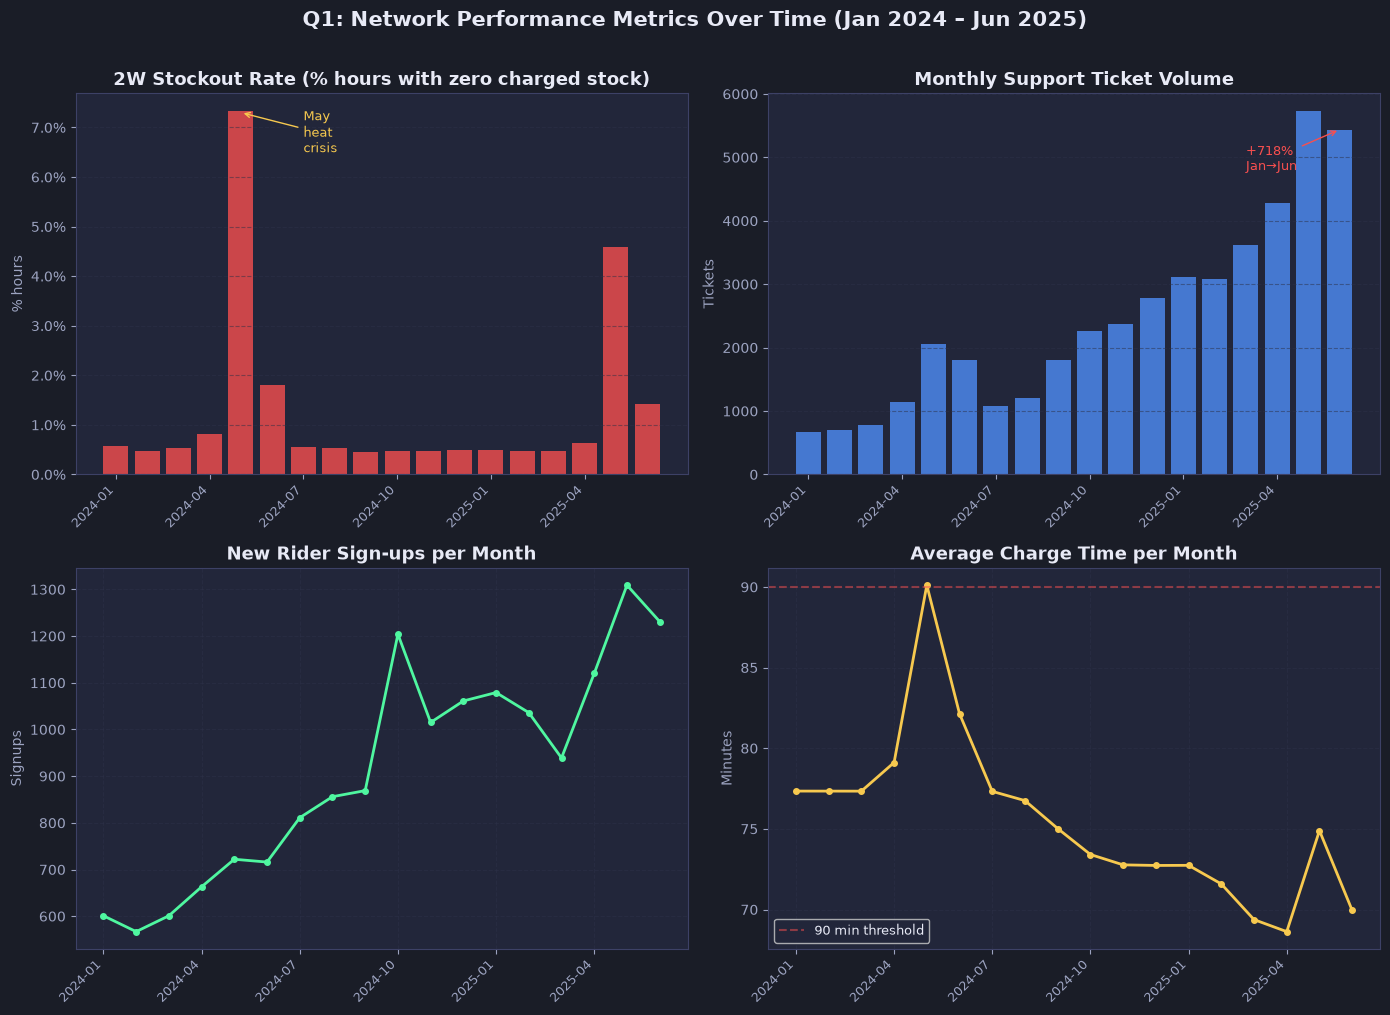

KEY FINDING: Ticket volume grew 718% (665→5,438/month) while rider sign-ups only ~2×.
The May 2024 and 2025 heat crises caused stockout spikes of 7.3% and 4.6% respectively.


In [5]:
# ============================================================
# Q1: NETWORK PERFORMANCE OVER TIME
# ============================================================

ok = shs[shs['telemetry_status']=='ok']
monthly_shs = ok.groupby('month').agg(
    total_hours=('station_id','count'),
    stockout_hours=('stockout_2w','sum'),
    avg_charge=('avg_charge_minutes','mean'),
    outage_min=('outage_minutes','mean'),
    quarantined=('packs_quarantined','mean')
).reset_index()
monthly_shs['stockout_rate_pct'] = monthly_shs['stockout_hours'] / monthly_shs['total_hours'] * 100
monthly_shs = monthly_shs[monthly_shs['month'] >= '2024-01']

monthly_tickets = tickets.groupby('month').size().reset_index(name='tickets')
monthly_tickets = monthly_tickets[(monthly_tickets['month'] >= '2024-01') & 
                                    (monthly_tickets['month'] <= '2025-06')]

riders['signup_month'] = riders['signup_date'].dt.to_period('M')
monthly_signups = riders.groupby('signup_month').size().reset_index(name='signups')
monthly_signups = monthly_signups[(monthly_signups['signup_month'] >= '2024-01') & 
                                    (monthly_signups['signup_month'] <= '2025-06')]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Q1: Network Performance Metrics Over Time (Jan 2024 – Jun 2025)', 
             fontsize=15, fontweight='bold', color='#e8eaf6', y=1.01)

months_str = [str(m) for m in monthly_shs['month']]
x = range(len(months_str))

# Stockout rate
ax = axes[0,0]
bars = ax.bar(x, monthly_shs['stockout_rate_pct'], color=ACCENT[3], alpha=0.8)
ax.set_title('2W Stockout Rate (% hours with zero charged stock)')
ax.set_xticks(x[::3]); ax.set_xticklabels(months_str[::3], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('% hours'); ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
# Annotate May spikes
ax.annotate('May\nheat\ncrisis', xy=(4, 7.3), xytext=(6, 6.5), fontsize=9, color='#f7c94f',
            arrowprops=dict(arrowstyle='->', color='#f7c94f'))
ax.grid(True, axis='y')

# Ticket volume
ax = axes[0,1]
mt_x = range(len(monthly_tickets))
ax.bar(mt_x, monthly_tickets['tickets'], color=ACCENT[0], alpha=0.8)
ax.set_title('Monthly Support Ticket Volume')
mt_labs = [str(m) for m in monthly_tickets['month']]
ax.set_xticks(list(mt_x)[::3]); ax.set_xticklabels(mt_labs[::3], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Tickets'); ax.grid(True, axis='y')
ax.annotate(f"+718%\nJan→Jun", xy=(17, 5438), xytext=(14, 4800), fontsize=9, color='#f74f4f',
            arrowprops=dict(arrowstyle='->', color='#f74f4f'))

# Rider signups
ax = axes[1,0]
su_x = range(len(monthly_signups))
ax.plot(su_x, monthly_signups['signups'],
        color=ACCENT[2], linewidth=2, marker='o', markersize=4)
ax.set_title('New Rider Sign-ups per Month')
ax.set_xticks(range(0, len(monthly_signups), 3))
ax.set_xticklabels([str(monthly_signups['signup_month'].iloc[i]) for i in range(0, len(monthly_signups), 3)], 
                    rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Signups'); ax.grid(True)

# Average charge time
ax = axes[1,1]
ax.plot(x, monthly_shs['avg_charge'], color=ACCENT[1], linewidth=2, marker='o', markersize=4)
ax.set_title('Average Charge Time per Month')
ax.set_xticks(x[::3]); ax.set_xticklabels(months_str[::3], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Minutes'); ax.grid(True)
ax.axhline(y=90, color='#f74f4f', linestyle='--', alpha=0.5, label='90 min threshold')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'q1_network_performance.png', dpi=150, bbox_inches='tight',
            facecolor='#1a1d27')
plt.show()

print('KEY FINDING: Ticket volume grew 718% (665→5,438/month) while rider sign-ups only ~2×.')
print('The May 2024 and 2025 heat crises caused stockout spikes of 7.3% and 4.6% respectively.')

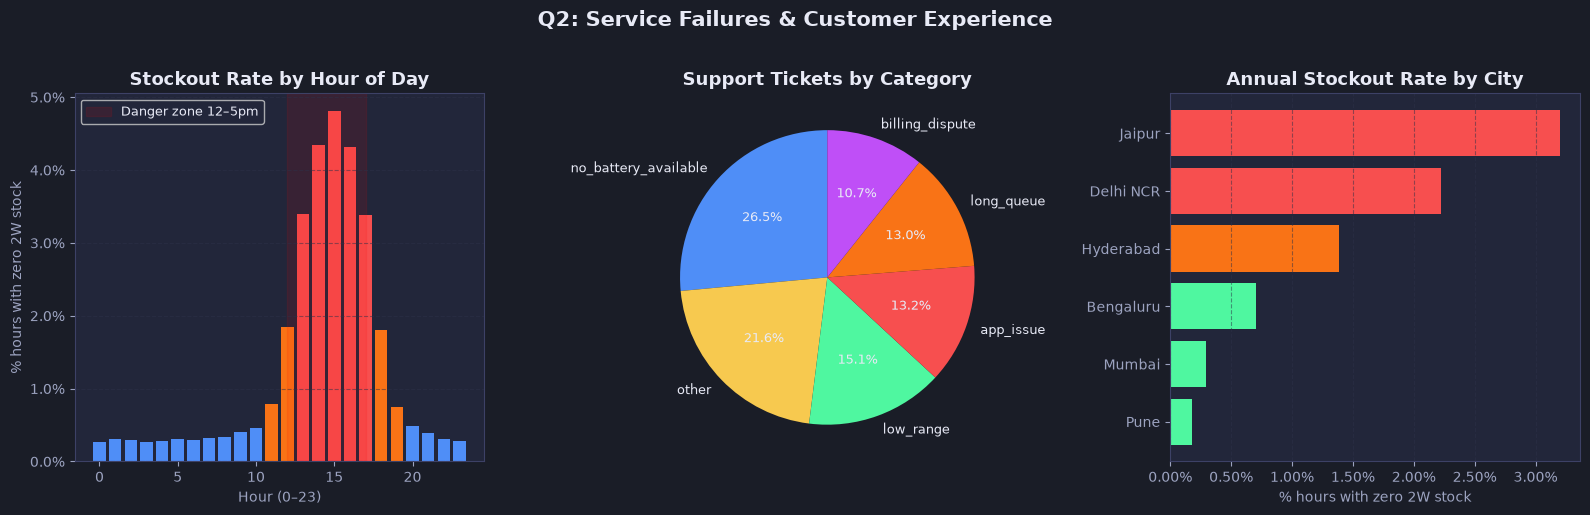

KEY FINDING: 70% of stockout hours occur between 12pm–5pm.
Jaipur (3.21%) and Delhi NCR (2.23%) have 5–10× higher stockout rates than Mumbai/Pune.
No battery available is the #1 complaint at 26.5% of all tickets.


In [6]:
# ============================================================
# Q2: SERVICE FAILURES & CUSTOMER EXPERIENCE
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Q2: Service Failures & Customer Experience', fontsize=15, fontweight='bold', 
             color='#e8eaf6', y=1.02)

# Hourly stockout rate
ax = axes[0]
hourly_stockout = ok.groupby('hour')['stockout_2w'].mean() * 100
colors = ['#f74f4f' if v > 2 else '#f97316' if v > 0.5 else '#4f8ef7' for v in hourly_stockout]
ax.bar(hourly_stockout.index, hourly_stockout.values, color=colors)
ax.set_title('Stockout Rate by Hour of Day')
ax.set_xlabel('Hour (0–23)'); ax.set_ylabel('% hours with zero 2W stock')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.axvspan(12, 17, alpha=0.1, color='red', label='Danger zone 12–5pm')
ax.legend(fontsize=9); ax.grid(True, axis='y')

# Ticket categories
ax = axes[1]
cat_counts = tickets['category'].value_counts()
wedges, texts, autotexts = ax.pie(cat_counts.values, labels=cat_counts.index,
    autopct='%1.1f%%', colors=ACCENT, startangle=90,
    textprops={'color':'#e8eaf6','fontsize':9})
ax.set_title('Support Tickets by Category')

# City stockout
ax = axes[2]
city_so = ok.groupby('city')['stockout_2w'].mean() * 100
city_so_sorted = city_so.sort_values(ascending=True)
bar_colors = ['#f74f4f' if v > 2 else '#f97316' if v > 1 else '#4ff7a0' for v in city_so_sorted]
ax.barh(city_so_sorted.index, city_so_sorted.values, color=bar_colors)
ax.set_title('Annual Stockout Rate by City')
ax.set_xlabel('% hours with zero 2W stock')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.grid(True, axis='x')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'q2_service_failures.png', dpi=150, bbox_inches='tight',
            facecolor='#1a1d27')
plt.show()

print('KEY FINDING: 70% of stockout hours occur between 12pm–5pm.')
print('Jaipur (3.21%) and Delhi NCR (2.23%) have 5–10× higher stockout rates than Mumbai/Pune.')
print('No battery available is the #1 complaint at 26.5% of all tickets.')

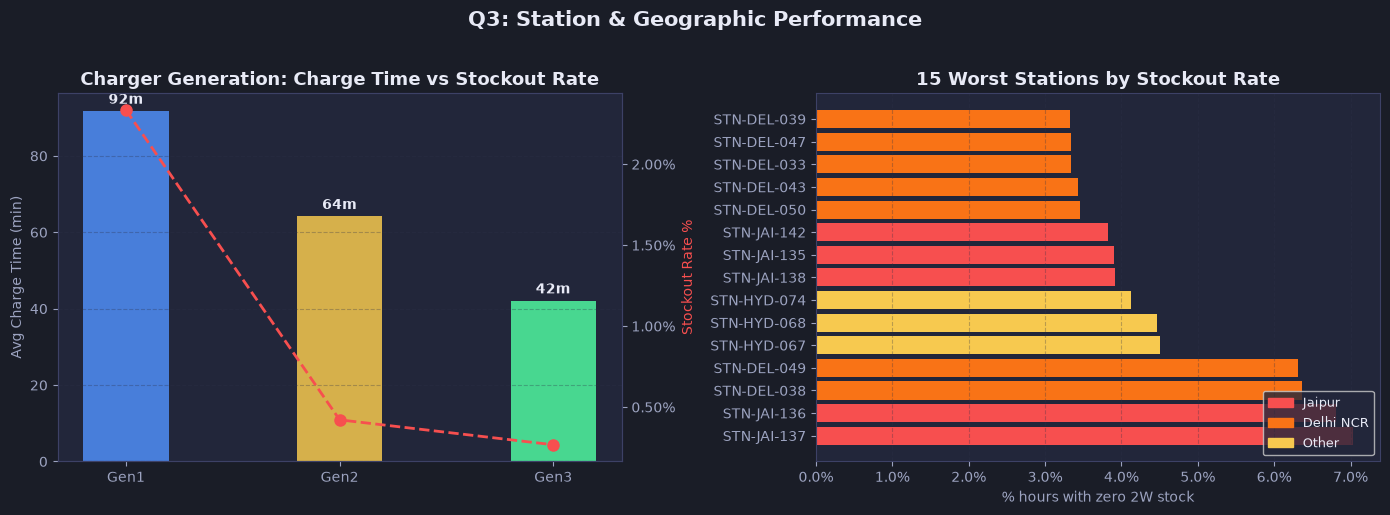

KEY FINDING: Gen1 charge time 91.8 min vs Gen3 42.1 min — a 2.2× throughput gap.
Gen1 stockout rate 2.33% vs Gen3 0.27% — an 8.7× difference.
ALL 15 worst-performing stations are in Jaipur or Delhi NCR (Gen1-heavy cities).


In [7]:
# ============================================================
# Q3: STATION & GEOGRAPHIC PATTERNS
# ============================================================

gen_perf = ok.groupby('charger_generation').agg(
    stockout_rate=('stockout_2w','mean'),
    charge_time=('avg_charge_minutes','mean'),
    total_hours=('station_id','count')
).reset_index()

# Worst stations
station_perf = ok.groupby('station_id').agg(
    stockout_rate=('stockout_2w','mean'),
    avg_charge=('avg_charge_minutes','mean'),
    quarantine=('packs_quarantined','mean'),
    obs=('station_id','count')
).reset_index()
worst15 = station_perf.nlargest(15,'stockout_rate')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Q3: Station & Geographic Performance', fontsize=15, fontweight='bold',
             color='#e8eaf6', y=1.02)

# Charge time by gen
ax = axes[0]
gens = gen_perf['charger_generation'].tolist()
charge_vals = gen_perf['charge_time'].tolist()
stockout_vals = [v*100 for v in gen_perf['stockout_rate'].tolist()]
x = np.arange(len(gens))
bars = ax.bar(x, charge_vals, color=ACCENT[:3], alpha=0.85, width=0.4, label='Charge Time (min)')
ax2 = ax.twinx()
ax2.plot(x, stockout_vals, 'o--', color='#f74f4f', linewidth=2, markersize=8, label='Stockout %')
ax.set_xticks(x); ax.set_xticklabels(gens)
ax.set_ylabel('Avg Charge Time (min)', color='#9ca3c0')
ax2.set_ylabel('Stockout Rate %', color='#f74f4f')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_title('Charger Generation: Charge Time vs Stockout Rate')
# Add value labels
for bar, v in zip(bars, charge_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{v:.0f}m', 
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='#e8eaf6')
ax.grid(True, axis='y', alpha=0.3)

# Worst 15 stations
ax = axes[1]
colors_15 = ['#f74f4f' if 'JAI' in s else '#f97316' if 'DEL' in s else '#f7c94f' 
             for s in worst15['station_id']]
ax.barh(worst15['station_id'], worst15['stockout_rate']*100, color=colors_15)
ax.set_title('15 Worst Stations by Stockout Rate')
ax.set_xlabel('% hours with zero 2W stock')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
# Legend
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#f74f4f',label='Jaipur'),Patch(color='#f97316',label='Delhi NCR'),
                    Patch(color='#f7c94f',label='Other')], fontsize=9, loc='lower right')
ax.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'q3_station_patterns.png', dpi=150, bbox_inches='tight',
            facecolor='#1a1d27')
plt.show()

print('KEY FINDING: Gen1 charge time 91.8 min vs Gen3 42.1 min — a 2.2× throughput gap.')
print('Gen1 stockout rate 2.33% vs Gen3 0.27% — an 8.7× difference.')
print('ALL 15 worst-performing stations are in Jaipur or Delhi NCR (Gen1-heavy cities).')

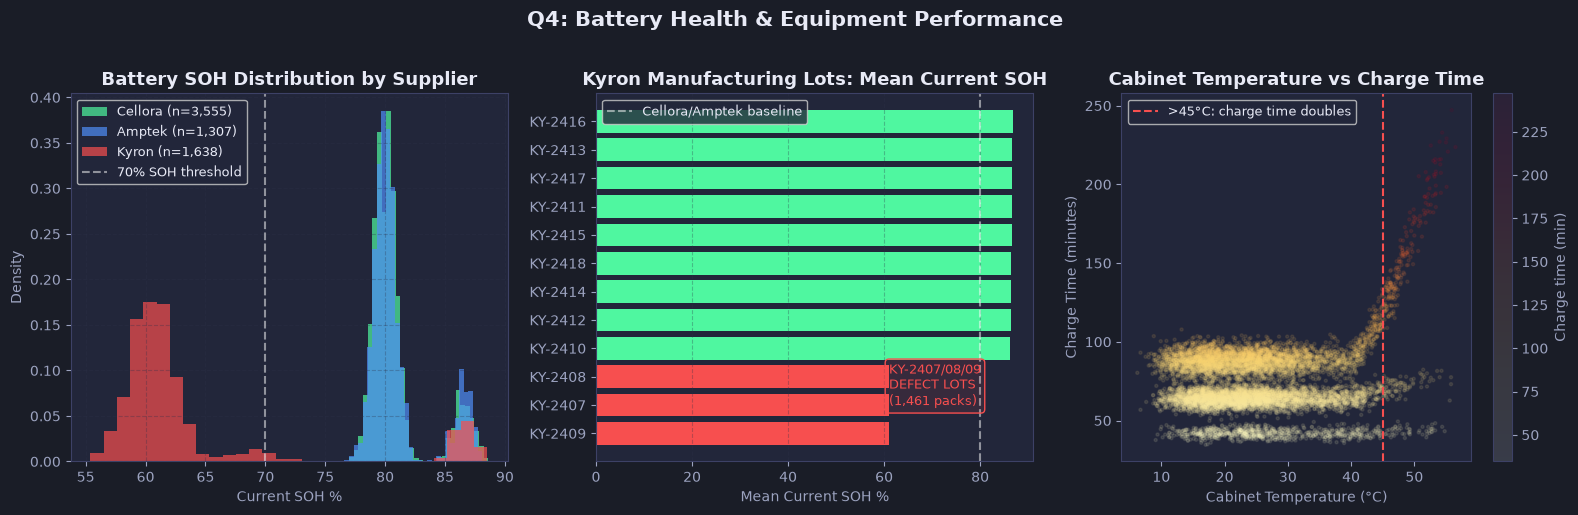

KEY FINDING: Kyron KY-2407/08/09 show 38% degradation vs expected 18%.
Mean SOH: Cellora=80.9% Amptek=81.0% Kyron=63.7%
Cabinet temps >45°C push charge time to 118+ min (118% of baseline) — directly causing May stockouts.


In [15]:

# ============================================================
# Q4: BATTERY & EQUIPMENT PERFORMANCE
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    'Q4: Battery Health & Equipment Performance',
    fontsize=15,
    fontweight='bold',
    color='#e8eaf6',
    y=1.02
)

# SOH distribution by supplier
ax = axes[0]

for i, (sup, color) in enumerate(zip(
    ['Cellora', 'Amptek', 'Kyron'],
    ['#4ff7a0', '#4f8ef7', '#f74f4f']
)):
    data = batteries[batteries['supplier'] == sup]['current_soh_pct']

    ax.hist(
        data,
        bins=30,
        alpha=0.7,
        color=color,
        label=f'{sup} (n={len(data):,})',
        density=True
    )

ax.set_xlabel('Current SOH %')
ax.set_ylabel('Density')
ax.set_title('Battery SOH Distribution by Supplier')
ax.axvline(
    x=70,
    color='white',
    linestyle='--',
    alpha=0.5,
    label='70% SOH threshold'
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)


# Kyron lot breakdown
ax = axes[1]

kyron = batteries[batteries['supplier'] == 'Kyron']

lot_soh = (
    kyron.groupby('manufacturing_lot')['current_soh_pct']
    .mean()
    .sort_values()
)

bar_colors = [
    '#f74f4f' if v < 70 else '#4ff7a0'
    for v in lot_soh.values
]

ax.barh(
    lot_soh.index,
    lot_soh.values,
    color=bar_colors
)

ax.set_xlabel('Mean Current SOH %')
ax.set_title('Kyron Manufacturing Lots: Mean Current SOH')

ax.axvline(
    x=80,
    color='white',
    linestyle='--',
    alpha=0.5,
    label='Cellora/Amptek baseline'
)

ax.legend(fontsize=9)
ax.grid(True, axis='x', alpha=0.3)

# Annotate defect lots
ax.annotate(
    'KY-2407/08/09\nDEFECT LOTS\n(1,461 packs)',
    xy=(61, 1),
    fontsize=9,
    color='#f74f4f',
    bbox=dict(
        boxstyle='round',
        facecolor=(247/255, 79/255, 79/255, 0.1),
        edgecolor='#f74f4f'
    )
)


# Cabinet temperature vs charge time
ax = axes[2]

temp_charge_data = ok[
    ['cabinet_temp_c', 'avg_charge_minutes']
].dropna()

temp_charge = temp_charge_data.sample(
    n=min(10000, len(temp_charge_data)),
    random_state=42
)

sc = ax.scatter(
    temp_charge['cabinet_temp_c'],
    temp_charge['avg_charge_minutes'],
    alpha=0.1,
    c=temp_charge['avg_charge_minutes'],
    cmap='YlOrRd',
    s=5
)

ax.set_xlabel('Cabinet Temperature (°C)')
ax.set_ylabel('Charge Time (minutes)')
ax.set_title('Cabinet Temperature vs Charge Time')

ax.axvline(
    x=45,
    color='#f74f4f',
    linestyle='--',
    label='>45°C: charge time doubles'
)

plt.colorbar(
    sc,
    ax=ax,
    label='Charge time (min)'
)

ax.legend(fontsize=9)


# Layout and save
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'q4_battery_performance.png',
    dpi=150,
    bbox_inches='tight',
    facecolor='#1a1d27'
)

plt.show()


# Key findings
print(
    'KEY FINDING: Kyron KY-2407/08/09 show '
    '38% degradation vs expected 18%.'
)

print(
    f'Mean SOH: '
    f'Cellora={batteries[batteries.supplier=="Cellora"]["current_soh_pct"].mean():.1f}% '
    f'Amptek={batteries[batteries.supplier=="Amptek"]["current_soh_pct"].mean():.1f}% '
    f'Kyron={batteries[batteries.supplier=="Kyron"]["current_soh_pct"].mean():.1f}%'
)

print(
    'Cabinet temps >45°C push charge time to 118+ min '
    '(118% of baseline) — directly causing May stockouts.'
)


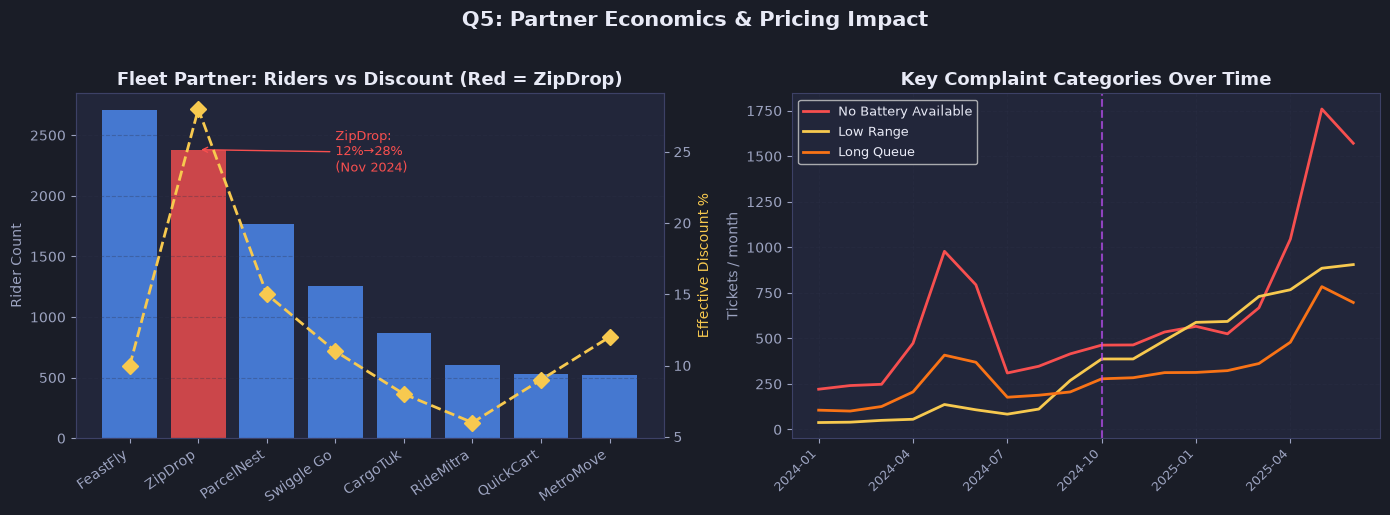

KEY FINDING: ZipDrop contract amended Nov 2024: 12%→28% discount + peak surcharge waived.
With 2,381 riders on volume-tiered contract, this is a significant per-swap margin erosion event.
Low_range tickets closely track Kyron commissioning timeline (Sep-Nov 2024).


In [9]:
# ============================================================
# Q5: PRICING & PARTNER ECONOMICS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Q5: Partner Economics & Pricing Impact', fontsize=15, fontweight='bold',
             color='#e8eaf6', y=1.02)

# Partner discount vs rider count
ax = axes[0]
fleet_riders = riders[riders['partner_id'].notna()].groupby('partner_id').size().reset_index(name='rider_count')
fleet_merged = fleet.merge(fleet_riders, on='partner_id', how='left')
fleet_merged['rider_count'] = fleet_merged['rider_count'].fillna(0)
fleet_merged['effective_discount'] = fleet_merged['discount_pct_after_amendment'].fillna(fleet_merged['discount_pct'])
fleet_merged = fleet_merged.sort_values('rider_count', ascending=False).head(8)

bar_colors = ['#f74f4f' if p == 'FP-03' else '#4f8ef7' for p in fleet_merged['partner_id']]
bars = ax.bar(fleet_merged['partner_name'], fleet_merged['rider_count'], color=bar_colors, alpha=0.8)
ax2 = ax.twinx()
ax2.plot(range(len(fleet_merged)), fleet_merged['effective_discount'], 'D--', 
         color='#f7c94f', linewidth=2, markersize=8)
ax.set_xticks(range(len(fleet_merged)))
ax.set_xticklabels(fleet_merged['partner_name'], rotation=35, ha='right')
ax.set_ylabel('Rider Count', color='#9ca3c0')
ax2.set_ylabel('Effective Discount %', color='#f7c94f')
ax.set_title('Fleet Partner: Riders vs Discount (Red = ZipDrop)')
# Annotate ZipDrop
ax.annotate('ZipDrop:\n12%→28%\n(Nov 2024)', xy=(1, 2381), xytext=(3, 2200),
            fontsize=9, color='#f74f4f',
            arrowprops=dict(arrowstyle='->', color='#f74f4f'))
ax.grid(True, axis='y', alpha=0.3)

# Monthly ticket categories trend
ax = axes[1]
cat_monthly = tickets.groupby(['month','category']).size().unstack(fill_value=0)
cat_monthly = cat_monthly[(cat_monthly.index >= '2024-01') & (cat_monthly.index <= '2025-06')]
months_range = [str(m) for m in cat_monthly.index]
x = range(len(months_range))
for cat, color in zip(['no_battery_available','low_range','long_queue'],
                       ['#f74f4f','#f7c94f','#f97316']):
    if cat in cat_monthly.columns:
        ax.plot(x, cat_monthly[cat], color=color, linewidth=2, label=cat.replace('_',' ').title())
ax.set_title('Key Complaint Categories Over Time')
ax.set_xticks(list(x)[::3])
ax.set_xticklabels(months_range[::3], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Tickets / month')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
# Annotate Kyron onset
ax.axvline(x=9, color='#bf4ff7', linestyle='--', alpha=0.7, label='Kyron commissioned')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'q5_pricing_partners.png', dpi=150, bbox_inches='tight',
            facecolor='#1a1d27')
plt.show()

print('KEY FINDING: ZipDrop contract amended Nov 2024: 12%→28% discount + peak surcharge waived.')
print('With 2,381 riders on volume-tiered contract, this is a significant per-swap margin erosion event.')
print('Low_range tickets closely track Kyron commissioning timeline (Sep-Nov 2024).')

=== RETENTION ANALYSIS ===
Riders signed up 2024+: 16,400
Of these, raised at least 1 ticket: 11,094 (67.6%)

Sign-up channel vs ticket rate:
signup_channel
partner_onboarding    0.691308
field_agent           0.685163
app_store             0.652275
referral              0.644527
Name: has_ticket, dtype: float64

City vs ticket rate:
city
Delhi NCR    0.733313
Hyderabad    0.727660
Jaipur       0.727360
Bengaluru    0.632728
Pune         0.630763
Mumbai       0.603943
Name: has_ticket, dtype: float64

Gen1 share of no_battery_available tickets: 55.4%
Gen1 share of stations: 51/152 = 33.6%


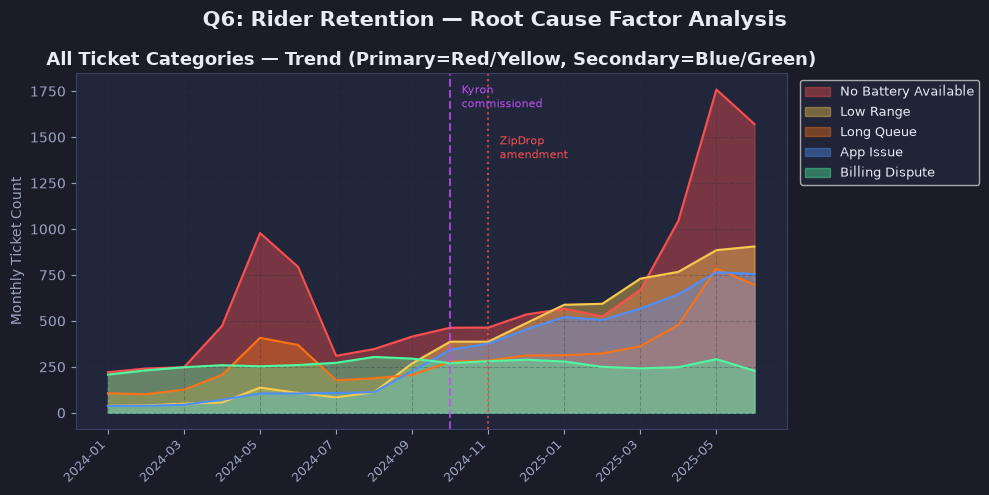


KEY FINDING: Gen1 stations generate 56% of no_battery_available tickets despite being 34% of stations.
Low_range tickets grew 2,282% (38→905/month) — tracking Kyron battery commissioning timeline.
Primary churn drivers: Gen1 stockouts + Kyron range degradation.
Secondary: peak-hour queues (correlated with Gen1), billing confusion (pricing pilot).


In [10]:
# ============================================================
# Q6: ROOT CAUSE ANALYSIS — RIDER RETENTION
# ============================================================

# Rider-ticket linkage
rider_ticket_summary = tickets.groupby('rider_id').agg(
    num_tickets=('ticket_id','count'),
    categories=('category', lambda x: x.tolist()),
    first_ticket=('created_ts','min')
).reset_index()

riders_enriched = riders.merge(rider_ticket_summary, on='rider_id', how='left')
riders_enriched['has_ticket'] = riders_enriched['num_tickets'].notna()
riders_enriched['ticket_count'] = riders_enriched['num_tickets'].fillna(0)
riders_2024plus = riders_enriched[riders_enriched['signup_date'] >= '2024-01-01']

print('=== RETENTION ANALYSIS ===')
print(f'Riders signed up 2024+: {len(riders_2024plus):,}')
print(f'Of these, raised at least 1 ticket: {riders_2024plus["has_ticket"].sum():,} ({riders_2024plus["has_ticket"].mean()*100:.1f}%)')

print('\nSign-up channel vs ticket rate:')
print(riders_2024plus.groupby('signup_channel')['has_ticket'].mean().sort_values(ascending=False))

print('\nCity vs ticket rate:')
print(riders_2024plus.groupby('city')['has_ticket'].mean().sort_values(ascending=False))

# Gen1 ticket concentration
gen1_stations_list = stations[stations['charger_generation']=='Gen1']['station_id'].tolist()
gen1_tickets = tickets[tickets['station_id'].isin(gen1_stations_list)]
gen1_no_batt = gen1_tickets[gen1_tickets['category']=='no_battery_available']
total_no_batt = tickets[tickets['category']=='no_battery_available']
print(f'\nGen1 share of no_battery_available tickets: {len(gen1_no_batt)/len(total_no_batt)*100:.1f}%')
print(f'Gen1 share of stations: {len(gen1_stations_list)}/{len(stations)} = {len(gen1_stations_list)/len(stations)*100:.1f}%')

# Visualize retention risk factors
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Q6: Rider Retention — Root Cause Factor Analysis', fontsize=15, 
             fontweight='bold', color='#e8eaf6')

cat_monthly = tickets.groupby(['month','category']).size().unstack(fill_value=0)
cat_monthly = cat_monthly[(cat_monthly.index >= '2024-01') & (cat_monthly.index <= '2025-06')]
months_range = [str(m) for m in cat_monthly.index]
x = range(len(months_range))

cat_colors = {'no_battery_available':'#f74f4f','low_range':'#f7c94f',
              'long_queue':'#f97316','app_issue':'#4f8ef7','billing_dispute':'#4ff7a0'}
for cat, color in cat_colors.items():
    if cat in cat_monthly.columns:
        ax.fill_between(x, cat_monthly[cat], alpha=0.4, color=color, label=cat.replace('_',' ').title())
        ax.plot(x, cat_monthly[cat], color=color, linewidth=1.5)

ax.set_xticks(list(x)[::2])
ax.set_xticklabels(months_range[::2], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Monthly Ticket Count')
ax.set_title('All Ticket Categories — Trend (Primary=Red/Yellow, Secondary=Blue/Green)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
# Mark key events
ax.axvline(x=9, color='#bf4ff7', linestyle='--', linewidth=1.5, alpha=0.8)
ax.text(9.3, ax.get_ylim()[1]*0.9, 'Kyron\ncommissioned', color='#bf4ff7', fontsize=8)
ax.axvline(x=10, color='#f74f4f', linestyle=':', linewidth=1.5, alpha=0.8)
ax.text(10.3, ax.get_ylim()[1]*0.75, 'ZipDrop\namendment', color='#f74f4f', fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'q6_retention.png', dpi=150, bbox_inches='tight',
            facecolor='#1a1d27')
plt.show()

print('\nKEY FINDING: Gen1 stations generate 56% of no_battery_available tickets despite being 34% of stations.')
print('Low_range tickets grew 2,282% (38→905/month) — tracking Kyron battery commissioning timeline.')
print('Primary churn drivers: Gen1 stockouts + Kyron range degradation.')
print('Secondary: peak-hour queues (correlated with Gen1), billing confusion (pricing pilot).')

In [11]:
# ============================================================
# SECTION 3: SUMMARY TABLE
# ============================================================

print('=' * 65)
print('VOLTRELAY ENERGY — ANALYTICS SUMMARY')
print('=' * 65)

print('\n📊 NETWORK OVERVIEW')
print(f'  Total registered riders: {len(riders):,}')
print(f'  Fleet-affiliated: {riders["partner_id"].notna().sum():,} ({riders["partner_id"].notna().mean()*100:.0f}%)')
print(f'  Active stations: {len(stations):,} across 6 cities')
print(f'  Station hourly observations: {len(shs):,}')
print(f'  Total support tickets: {len(tickets):,}')

print('\n⚡ SERVICE QUALITY')
so_rate = ok['stockout_2w'].mean()*100
print(f'  Overall 2W stockout rate: {so_rate:.2f}%')
print(f'  Peak hour (3pm) stockout rate: {ok[ok.hour==15]["stockout_2w"].mean()*100:.2f}%')
print(f'  Gen1 stockout rate: {ok[ok.charger_generation=="Gen1"]["stockout_2w"].mean()*100:.2f}%')
print(f'  Gen3 stockout rate: {ok[ok.charger_generation=="Gen3"]["stockout_2w"].mean()*100:.2f}%')

print('\n🔋 BATTERY HEALTH')
for sup in ['Cellora','Amptek','Kyron']:
    b = batteries[batteries['supplier']==sup]
    print(
        f'  {sup}: {len(b):,} packs, '
        f'mean SOH = {b["current_soh_pct"].mean():.1f}%, '
        f'mean degradation = {b["soh_degradation"].mean():.1f}%'
    )
kyron_bad = batteries[(batteries['supplier']=='Kyron') & 
                       (batteries['manufacturing_lot'].isin(['KY-2407','KY-2408','KY-2409']))]
print(f'  Kyron defect lots (KY-2407/08/09): {len(kyron_bad):,} packs = {len(kyron_bad)/len(batteries)*100:.1f}% of fleet')

print('\n📈 TICKET TREND')
jan24_t = tickets[tickets['month']=='2024-01'].shape[0]
jun25_t = tickets[tickets['month']=='2025-06'].shape[0]
print(f'  Jan 2024: {jan24_t:,} tickets')
print(f'  Jun 2025: {jun25_t:,} tickets')
print(f'  Growth: +{(jun25_t/jan24_t-1)*100:.0f}%')

print('\n💸 KEY PRICING EVENT')
print('  ZipDrop (FP-03): discount amended Nov 2024 from 12% → 28%')
print('  Peak surcharge NOT billable to ZipDrop (12% of all fleet riders)')

print('\n🎯 TOP 3 RECOMMENDATIONS')
print('  1. [IMMEDIATE] Quarantine Kyron KY-2407/08/09 batteries (1,461 packs at 61% SOH)')
print('  2. [SHORT-TERM] Deploy Gen3 upgrades at 23 Gen1 stations in Jaipur & Delhi NCR')
print('  3. [IMMEDIATE] Renegotiate ZipDrop contract to reinstate peak surcharge billing')
print('=' * 65)

VOLTRELAY ENERGY — ANALYTICS SUMMARY

📊 NETWORK OVERVIEW
  Total registered riders: 20,000
  Fleet-affiliated: 12,372 (62%)
  Active stations: 152 across 6 cities
  Station hourly observations: 1,487,712
  Total support tickets: 44,000

⚡ SERVICE QUALITY
  Overall 2W stockout rate: 1.27%
  Peak hour (3pm) stockout rate: 4.81%
  Gen1 stockout rate: 2.33%
  Gen3 stockout rate: 0.27%

🔋 BATTERY HEALTH
  Cellora: 3,555 packs, mean SOH = 80.9%, mean degradation = 18.3%
  Amptek: 1,307 packs, mean SOH = 81.0%, mean degradation = 18.2%
  Kyron: 1,638 packs, mean SOH = 63.7%, mean degradation = 35.5%
  Kyron defect lots (KY-2407/08/09): 1,461 packs = 22.5% of fleet

📈 TICKET TREND
  Jan 2024: 665 tickets
  Jun 2025: 5,438 tickets
  Growth: +718%

💸 KEY PRICING EVENT
  ZipDrop (FP-03): discount amended Nov 2024 from 12% → 28%
  Peak surcharge NOT billable to ZipDrop (12% of all fleet riders)

🎯 TOP 3 RECOMMENDATIONS
  1. [IMMEDIATE] Quarantine Kyron KY-2407/08/09 batteries (1,461 packs at 61% S